# Blocked cross-validation of the hypothesis ladder (Table S2)

The model comparisons in the main analysis use PSIS-LOO, i.e. leave-one-**hour**-out. Hourly
observations are autocorrelated, so the nested ladder (`model_0` → `model_1` → `model_2` → `model_3` →
`model_4_ord`; hypotheses H0–H3) is re-scored here with exact 10-fold cross-validation in which
contiguous **6 h** and **12 h** blocks are held out together (maximum-likelihood refits of the same
cumulative-logit models; 2 species × 5 models × 3 block schemes × 10 folds = 300 refits). A random-hour
10-fold split with the same refits is the control.

Adapted from `fourier_harmonics_hour_vs_day_loo.ipynb` (Sections 0–6 and 9), restricted to K = 2
harmonics, the value used in the paper.

**Paper items produced here:** Table S2 (`tables/TableS2_blocked_cross_validation.csv`) and the block
lengths quoted in its caption (autocorrelation of the pointwise ΔELPD, `tables/supporting/block_length_delta_acf_summary.csv`).
The 1 h (PSIS-LOO) column uses the K = 2 Bayesian fits shared with `01_main_analysis.ipynb`.

## 0. Setup

In [1]:
import time
import warnings
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D

import arviz as az
import bambi as bmb
from joblib import Parallel, delayed
from patsy import dmatrix
from statsmodels.miscmodels.ordinal_model import OrderedModel

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

np.set_printoptions(linewidth=150)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)


# ══ FIGURE STYLE TOGGLES (mirrors the main notebook) ═════════════════════════
FONT_SCALE = 1.0
LINE_SCALE = 1.0

FS_TITLE      = 20 * FONT_SCALE
FS_SUPTITLE   = 21 * FONT_SCALE
FS_LABEL      = 21 * FONT_SCALE
FS_TICK       = 15 * FONT_SCALE
FS_LEGEND     = 16 * FONT_SCALE

LW_MAIN      = 2.8 * LINE_SCALE
LW_SECONDARY = 2.2 * LINE_SCALE
LW_AUX       = 1.6 * LINE_SCALE
LW_SPINE     = 1.2 * LINE_SCALE
LW_GRID      = 1.0 * LINE_SCALE
CAPSIZE      = 5.0 * LINE_SCALE
# ═════════════════════════════════════════════════════════════════════════════

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": FS_TICK,
    "axes.titlesize": FS_TITLE,
    "axes.labelsize": FS_LABEL,
    "figure.titlesize": FS_SUPTITLE,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "legend.fontsize": FS_LEGEND,
    "figure.figsize": (14, 6),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": LW_GRID,
    "lines.linewidth": LW_MAIN,
    "axes.linewidth": LW_SPINE,
    "xtick.major.width": LW_SPINE,
    "ytick.major.width": LW_SPINE,
    "axes.spines.top": False,
    "axes.spines.right": True,
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "STIXGeneral", "DejaVu Serif", "Times New Roman"],
    "mathtext.fontset": "cm",
    # cmr10 has no U+2212 glyph; use the ASCII hyphen so negative
    # tick labels render as -0.10 rather than a missing-glyph box.
    "axes.unicode_minus": False,
})

SPECIES = ["Gastrotheca chrysosticta", "Oreobates berdemenos"]
SP_SHORT = {
    "Gastrotheca chrysosticta": "G. chrysosticta",
    "Oreobates berdemenos": "O. berdemenos",
}


def mathit(s: str) -> str:
    """Species names through mathtext: cmr10 has no italic face."""
    return r"$\mathit{" + s.replace(" ", r"\ ") + "}$"


import frogcall as fc

PLOT_DIR = fc.FIG_DIR


def savefig(fig, name, formats=("pdf", "png")):
    """Save a figure into figures/ (none of the figures here is in the paper)."""
    fc.save_figure(fig, f"extra_blockcv_{name}", formats)


print("Setup complete. Figures will be saved to:", PLOT_DIR.resolve())

Setup complete. Figures will be saved to: /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/figures


## 1. Configuration

`HS_K_VALUES` is the harmonic sweep. K = 2–5 are on disk for every rung; any other K
(here K = 1 and K = 6) costs 5 rungs × 2 species MCMC runs of ≈ 3 min each, plus k-fold
refits (fast, run in parallel). `HS_VARY` and the sampler settings must stay as below for the
caches of `fourier_harmonics_sensitivity.ipynb` to be valid.

In [2]:
# ── Harmonic sweep ───────────────────────────────────────────────────────────
HS_K_VALUES = [2]                  # harmonics per cycle (the paper's K)
HS_K_REF    = 2                    # the count used in the main analysis
HS_VARY     = "both"               # "both" | "diel" | "seasonal"

# ── Bayesian (hour PSIS-LOO) — identical to the main notebook, Section 4 ─────
BAYES_DRAWS         = 1000
BAYES_TUNE          = 1000
BAYES_CHAINS        = 4
BAYES_CORES         = 1
BAYES_TARGET_ACCEPT = 0.9
BAYES_SEED          = 42
HS_PRIORS = {"common": bmb.Prior("Normal", mu=0, sigma=1)}

# ── k-fold refits (day-blocked CV and the random-hour control) — as in §10 ───
CV_K, CV_SEED = 10, 42
CV_N_JOBS     = -1        # joblib workers for the ML refits
CV_REFIT      = False     # True → ignore cached held-out log-likelihoods

DECISIVE_SE = 2.0         # a step is supported when Δelpd > DECISIVE_SE × SE(Δ)

# ── Caching ──────────────────────────────────────────────────────────────────
HS_MODEL_DIR = fc.MODEL_DIR
HS_TABLE_DIR = fc.TABLE_DIR / "supporting"
HS_ELPD_DIR  = fc.CV_DIR
for _d in (HS_MODEL_DIR, HS_TABLE_DIR, HS_ELPD_DIR):
    _d.mkdir(parents=True, exist_ok=True)

HS_REFIT       = False    # True → resample even when a cached posterior exists
HS_SAVE_LOGLIK = False    # True → keep the ~360 MB log_likelihood group in the .nc

SECTION10_CSV = HS_TABLE_DIR / "loo_hour_vs_day_ladder.csv"   # main notebook, K = 2


def hs_k_pair(K: int) -> Tuple[int, int]:
    """(diel harmonics, seasonal harmonics) for grid point K."""
    if HS_VARY == "both":
        return K, K
    if HS_VARY == "diel":
        return K, HS_K_REF
    if HS_VARY == "seasonal":
        return HS_K_REF, K
    raise ValueError(f"HS_VARY must be 'both', 'diel' or 'seasonal', got {HS_VARY!r}")


SCHEMES = {
    "hour_psis":  "Leave-one-hour-out (PSIS-LOO)",
    "day_kfold":  "Leave-one-day-out (day-blocked 10-fold)",
    "hour_kfold": "Random-hour 10-fold (control)",
}
SCHEME_STYLE = {
    "hour_psis":  dict(color="#4c72b0", marker="o", ls="-",  lw=LW_SECONDARY),
    "day_kfold":  dict(color="#dd8452", marker="s", ls="-",  lw=LW_SECONDARY),
    "hour_kfold": dict(color="0.55",    marker="^", ls="--", lw=LW_AUX),
}

print(f"K sweep: {HS_K_VALUES} (varying {HS_VARY}); reference K = {HS_K_REF}")
for _K in HS_K_VALUES:
    _kd, _ks = hs_k_pair(_K)
    print(f"  K={_K}: {_kd} diel + {_ks} seasonal harmonics → {2 * (_kd + _ks)} harmonic coefficients")

K sweep: [2] (varying both); reference K = 2
  K=2: 2 diel + 2 seasonal harmonics → 8 harmonic coefficients


## 2. Data

Row filter copied verbatim from the main notebook (including the `other_calling_lag1`
column, whose lag drops the first timestamp), so that every model at every K is scored on
the same 11 302 rows as the cached fits. All harmonics up to `max(HS_K_VALUES)` are built
once; they never contain missing values, so K does not change the rows.

In [3]:
DATA_PATH = fc.DATA_PATH
TEMP_COL, RH_COL = "Temp", "RH%"

df = pd.read_csv(DATA_PATH)
df["DateTime"] = pd.to_datetime(df["DateTime"], errors="coerce")
df = df.set_index("DateTime").sort_index()
K_MAX = max(HS_K_VALUES)


def zscore(series: pd.Series) -> pd.Series:
    return (series - series.mean()) / series.std(ddof=0)


def add_fourier_terms(d: pd.DataFrame, k_diel: int, k_seas: int) -> pd.DataFrame:
    """sin/cos pairs for harmonics 1..k of the 24 h and 366 d cycles."""
    two_pi = 2 * np.pi
    for j in range(1, k_diel + 1):
        d[f"sin_h{j}"] = np.sin(j * two_pi * d["hour"] / 24.0)
        d[f"cos_h{j}"] = np.cos(j * two_pi * d["hour"] / 24.0)
    for j in range(1, k_seas + 1):
        d[f"sin_d{j}"] = np.sin(j * two_pi * d["doy"] / 366.0)
        d[f"cos_d{j}"] = np.cos(j * two_pi * d["doy"] / 366.0)
    return d


def prepare_species_df(df_in: pd.DataFrame, response_col: str) -> pd.DataFrame:
    df_local = df_in.copy()
    df_local["temp_z"] = zscore(pd.to_numeric(df_local[TEMP_COL], errors="coerce"))
    df_local["rh_z"]   = zscore(pd.to_numeric(df_local[RH_COL],   errors="coerce"))
    df_local["hour"] = df_local.index.hour
    df_local["doy"]  = df_local.index.dayofyear
    df_local = add_fourier_terms(df_local, K_MAX, K_MAX)

    other_col = [c for c in SPECIES if c != response_col][0]
    df_local["other_calling_ord"]  = pd.to_numeric(df_local[other_col], errors="coerce")
    df_local["other_calling_bin"]  = (df_local["other_calling_ord"] > 0).astype(int)
    df_local["other_calling_lag1"] = df_local["other_calling_bin"].shift(1)
    df_local["response_raw"]       = pd.to_numeric(df_local[response_col], errors="coerce")

    harmonic_cols = [f"{f}_{c}{j}" for c in ("h", "d") for j in range(1, K_MAX + 1)
                     for f in ("sin", "cos")]
    model_cols = ["response_raw", "temp_z", "rh_z", "other_calling_ord", "other_calling_bin",
                  "other_calling_lag1", "hour", "doy"] + harmonic_cols
    df_model = df_local[model_cols].dropna()

    response_cat = pd.Categorical(df_model["response_raw"], ordered=True)
    df_model["response_code"] = response_cat.codes
    df_model["response_cat"]  = response_cat
    return df_model


species_data = {sp: prepare_species_df(df, sp) for sp in SPECIES}
N_OBS = {sp: int(d.shape[0]) for sp, d in species_data.items()}
N_DAYS = {sp: int(d.index.normalize().nunique()) for sp, d in species_data.items()}
print("Rows per species:", N_OBS)
print("Calendar days per species:", N_DAYS)

Rows per species: {'Gastrotheca chrysosticta': 11302, 'Oreobates berdemenos': 11302}
Calendar days per species: {'Gastrotheca chrysosticta': 471, 'Oreobates berdemenos': 471}


## 3. The ladder

In [4]:
BLOCKS = [
    ("model_0",     "Temporal only",            "—",  []),
    ("model_1",     "+ weather",                "H0", ["temp_z", "rh_z"]),
    ("model_2",     "+ non-linear weather",     "H1", ["I(temp_z ** 2)", "I(rh_z ** 2)"]),
    ("model_3",     "+ T × RH interaction",     "H2", ["temp_z:rh_z"]),
    ("model_4_ord", "+ heterospecific calling", "H3", ["other_calling_ord"]),
]
LADDER  = [b[0] for b in BLOCKS]
LM_NAME = {b[0]: b[1] for b in BLOCKS}
LM_HYP  = {b[0]: b[2] for b in BLOCKS}
STEPS   = [(LM_HYP[LADDER[i + 1]], LM_NAME[LADDER[i + 1]], LADDER[i + 1], LADDER[i])
           for i in range(len(LADDER) - 1)]          # (hyp, adds, richer, simpler)
HYPS    = [s[0] for s in STEPS]
HYP_SHORT = {"H0": "weather", "H1": "non-linear", "H2": r"T$\times$RH", "H3": "other species"}


def fourier_terms(K: int) -> List[str]:
    kd, ks = hs_k_pair(K)
    return ([t for j in range(1, kd + 1) for t in (f"sin_h{j}", f"cos_h{j}")]
            + [t for j in range(1, ks + 1) for t in (f"sin_d{j}", f"cos_d{j}")])


def ladder_terms(model: str, K: int) -> List[str]:
    terms = list(fourier_terms(K))
    for name, _, _, block in BLOCKS:
        terms += block
        if name == model:
            return terms
    raise KeyError(model)


def ladder_formula(model: str, K: int, response: str = "response_cat") -> str:
    return f"{response} ~ " + " + ".join(ladder_terms(model, K))


# Guard: at K = 2 the top rung must be the main notebook's model_4_ord, term for term.
assert ladder_formula("model_4_ord", 2, "response_code") == (
    "response_code ~ sin_h1 + cos_h1 + sin_h2 + cos_h2 + sin_d1 + cos_d1 + sin_d2 + cos_d2 "
    "+ temp_z + rh_z + I(temp_z ** 2) + I(rh_z ** 2) + temp_z:rh_z + other_calling_ord")
print("✓ K=2 top rung matches model_4_ord in the main notebook")


# ── Cache paths (shared with fourier_harmonics_sensitivity.ipynb) ────────────
def _tag(sp: str) -> str:
    return sp.replace(" ", "_")


def nc_path(sp: str, m: str, K: int) -> Path:
    return HS_MODEL_DIR / f"{m}_K{K}{HS_VARY[0]}_{_tag(sp)}.nc"


def elpd_path(sp: str, m: str, K: int) -> Path:
    stem = "" if m == "model_4_ord" else f"{m}_"     # model_4_ord predates the per-rung naming
    return HS_ELPD_DIR / f"elpd_pointwise_{stem}K{K}{HS_VARY[0]}_{_tag(sp)}.npz"


def cv_path(sp: str, m: str, K: int, scheme: str) -> Path:
    return HS_ELPD_DIR / f"cv_loglik_{scheme}_{m}_K{K}{HS_VARY[0]}_{_tag(sp)}.npz"


GRID = [(sp, m, K) for sp in SPECIES for K in HS_K_VALUES for m in LADDER]
print(f"\n{len(GRID)} (species, rung, K) combinations")

✓ K=2 top rung matches model_4_ord in the main notebook

10 (species, rung, K) combinations


## 4. Leave-one-hour-out: Bayesian fits and PSIS-LOO

For each (species, rung, K): if the pointwise elpd is cached it is read (and the slim
posterior loaded for convergence diagnostics); otherwise the model is sampled with the main
notebook's settings, PSIS-LOO is computed while the log-likelihood is in memory, the pointwise
elpd is saved as `.npz`, and the posterior is cached without the ~360 MB log-likelihood group.

In [5]:
def diagnostics(idata) -> Dict[str, float]:
    try:
        diag = az.summary(idata, kind="diagnostics").apply(pd.to_numeric, errors="coerce")
    except Exception:
        diag = az.summary(idata).apply(pd.to_numeric, errors="coerce")
    div = (int(idata.sample_stats["diverging"].sum())
           if "sample_stats" in idata.children and "diverging" in idata.sample_stats else np.nan)
    return {"divergences": div,
            "max_r_hat": float(diag["r_hat"].max()) if "r_hat" in diag else np.nan,
            "min_ess_bulk": float(diag["ess_bulk"].min()) if "ess_bulk" in diag else np.nan}


def fit_or_load(sp: str, m: str, K: int):
    """Return (pointwise elpd, loo stats, diagnostics, source) from the shared cache."""
    fit = fc.fit_cached(ladder_formula(m, K), species_data[sp], sp, f"{m}_K{K}")
    source = "cache" if np.isnan(fit["seconds"]) else f"sampled ({fit['seconds'] / 60:.1f} min)"
    return fit["elpd_i"], fit["loo"], diagnostics(fit["idata"]), source


psis_elpd_i = {}     # (species, rung, K) → pointwise elpd
_rows = []
for sp, m, K in GRID:
    elpd_i, st, diag, source = fit_or_load(sp, m, K)
    assert len(elpd_i) == N_OBS[sp], f"{sp} {m} K={K}: {len(elpd_i)} ≠ {N_OBS[sp]} rows"
    psis_elpd_i[(sp, m, K)] = elpd_i
    _rows.append({"species": sp, "species_short": SP_SHORT[sp], "K": K, "model": m,
                  "n_coef": len(ladder_terms(m, K)), **st, **diag, "source": source})

psis_metrics = pd.DataFrame(_rows)
psis_metrics.to_csv(HS_TABLE_DIR / "blockcv_psis_metrics.csv", index=False)
display(psis_metrics[["species_short", "model", "elpd_loo", "loo_se", "p_loo", "n_pareto_bad",
                      "divergences", "max_r_hat", "min_ess_bulk", "source"]].round(2))

G. chrysosticta   model_0_K2       N(0, 1)  loaded from cache (model_0_K2_sd1_Gastrotheca_chrysosticta_dccf9189)
G. chrysosticta   model_1_K2       N(0, 1)  loaded from cache (model_1_K2_sd1_Gastrotheca_chrysosticta_3c482c75)


G. chrysosticta   model_2_K2       N(0, 1)  loaded from cache (model_2_K2_sd1_Gastrotheca_chrysosticta_824e968f)


G. chrysosticta   model_3_K2       N(0, 1)  loaded from cache (model_3_K2_sd1_Gastrotheca_chrysosticta_a04808a9)


G. chrysosticta   model_4_ord_K2   N(0, 1)  loaded from cache (model_4_ord_K2_sd1_Gastrotheca_chrysosticta_8dc8321c)


O. berdemenos     model_0_K2       N(0, 1)  loaded from cache (model_0_K2_sd1_Oreobates_berdemenos_dccf9189)
O. berdemenos     model_1_K2       N(0, 1)  loaded from cache (model_1_K2_sd1_Oreobates_berdemenos_3c482c75)


O. berdemenos     model_2_K2       N(0, 1)  loaded from cache (model_2_K2_sd1_Oreobates_berdemenos_824e968f)


O. berdemenos     model_3_K2       N(0, 1)  loaded from cache (model_3_K2_sd1_Oreobates_berdemenos_a04808a9)


O. berdemenos     model_4_ord_K2   N(0, 1)  loaded from cache (model_4_ord_K2_sd1_Oreobates_berdemenos_8dc8321c)


,species_short,model,elpd_loo,loo_se,p_loo,n_pareto_bad,divergences,max_r_hat,min_ess_bulk,source
0,G. chrysosticta,model_0,-3027.97,71.75,9.52,0.0,0,1.0,2428.0,cache
1,G. chrysosticta,model_1,-2645.28,67.99,11.39,0.0,0,1.0,2170.0,cache
2,G. chrysosticta,model_2,-2540.18,68.07,13.10,0.0,0,1.0,2295.0,cache
3,G. chrysosticta,model_3,-2538.32,68.36,14.40,0.0,0,1.0,2372.0,cache
4,G. chrysosticta,model_4_ord,-2539.06,68.39,15.53,0.0,0,1.0,2483.0,cache
5,O. berdemenos,model_0,-2319.25,63.56,8.30,0.0,0,1.0,2524.0,cache
6,O. berdemenos,model_1,-2254.55,61.71,10.04,0.0,0,1.0,2711.0,cache
7,O. berdemenos,model_2,-2242.74,61.37,11.58,0.0,0,1.0,2183.0,cache
8,O. berdemenos,model_3,-2225.17,61.07,12.68,1.0,0,1.0,1727.0,cache
9,O. berdemenos,model_4_ord,-2224.28,61.07,13.72,0.0,0,1.0,1494.0,cache


## 5. Leave-one-day-out (and the random-hour control): exact k-fold refits

Exactly §10 of the main notebook: the cumulative-logit models are refitted by maximum
likelihood on each training fold (a Bayesian refit per fold is prohibitive; with ~11k rows
and N(0, 1) priors the ML and posterior-mean fits are practically identical), and
log p(yᵢ | xᵢ, training folds) is recorded for every held-out row. Folds are drawn once per
species with the same seed and **reused at every K**, so the K comparison is paired too.

In [6]:
def make_folds(d: pd.DataFrame):
    """(day labels, random-hour folds, day folds) — the same RNG sequence as §10."""
    day = d.index.normalize().values
    rng = np.random.default_rng(CV_SEED)
    fold_hour = rng.permutation(np.arange(len(d)) % CV_K)
    ud = np.unique(day)
    fd = dict(zip(rng.permutation(ud), np.arange(len(ud)) % CV_K))
    return day, fold_hour, np.array([fd[x] for x in day])


def cv_loglik(y: np.ndarray, X: pd.DataFrame, fold: np.ndarray, n_folds: int):
    """Held-out log-likelihood of every row by exact refit; also the count of non-converged fits."""
    out, n_bad = np.full(len(y), np.nan), 0
    for k in range(n_folds):
        te = fold == k
        res = OrderedModel(pd.Series(y[~te], index=X.index[~te]), X[~te], distr="logit") \
            .fit(method="bfgs", disp=False, maxiter=2000)
        n_bad += int(not res.mle_retvals.get("converged", True))
        p = np.clip(np.asarray(res.predict(exog=X[te])), 1e-12, 1.0)
        out[te] = np.log(p[np.arange(te.sum()), y[te]])
    return out, n_bad


FOLDS = {sp: dict(zip(("day", "hour_kfold", "day_kfold"), make_folds(species_data[sp])))
         for sp in SPECIES}

_todo = [(sp, m, K, sc) for sp, m, K in GRID for sc in ("hour_kfold", "day_kfold")
         if CV_REFIT or not cv_path(sp, m, K, sc).exists()]
print(f"{2 * len(GRID) - len(_todo)} k-fold runs cached, {len(_todo)} to compute "
      f"({len(_todo) * CV_K} ML refits)")

if _todo:
    _t0 = time.time()

    def _job(sp, m, K, sc):
        d = species_data[sp]
        X = dmatrix("0 + " + " + ".join(ladder_terms(m, K)), d, return_type="dataframe")
        return cv_loglik(d["response_code"].values, X, FOLDS[sp][sc], CV_K)

    _out = Parallel(n_jobs=CV_N_JOBS, verbose=2)(delayed(_job)(*t) for t in _todo)
    for (sp, m, K, sc), (ll, n_bad) in zip(_todo, _out):
        np.savez_compressed(cv_path(sp, m, K, sc), loglik_i=ll, n_nonconverged=n_bad)
    print(f"done in {(time.time() - _t0) / 60:.1f} min")

cv_loglik_i, _conv = {}, []
for sp, m, K in GRID:
    for sc in ("hour_kfold", "day_kfold"):
        z = np.load(cv_path(sp, m, K, sc))
        cv_loglik_i[(sp, m, K, sc)] = z["loglik_i"]
        _conv.append(int(z["n_nonconverged"]))
assert all(np.isfinite(v).all() for v in cv_loglik_i.values())
print(f"✓ {len(cv_loglik_i)} k-fold runs loaded; non-converged fold fits: {sum(_conv)} "
      f"of {len(_conv) * CV_K}")

0 k-fold runs cached, 20 to compute (200 ML refits)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=-1)]: Done  16 out of  20 | elapsed:  1.8min remaining:   26.7s


[Parallel(n_jobs=-1)]: Done  20 out of  20 | elapsed:  2.4min finished


done in 2.4 min
✓ 20 k-fold runs loaded; non-converged fold fits: 0 of 200


## 6. Δelpd for every hypothesis × K × scheme

Each hypothesis is the step from the rung below to the rung that adds its block. For the two
hour schemes the SE is √n · sd of the pointwise difference; for the day scheme Δelpd is
summed within each calendar day and SE = √D · sd over the D days, so within-day dependence is
not double-counted.

In [7]:
def contrast(diff: np.ndarray, cluster: np.ndarray) -> Tuple[float, float]:
    s = pd.Series(diff).groupby(cluster).sum()
    return float(diff.sum()), float(np.sqrt(len(s) * s.var(ddof=1)))


def pointwise(sp, m, K, scheme):
    return psis_elpd_i[(sp, m, K)] if scheme == "hour_psis" else cv_loglik_i[(sp, m, K, scheme)]


_rows = []
for sp in SPECIES:
    cluster = {"hour_psis": np.arange(N_OBS[sp]), "hour_kfold": np.arange(N_OBS[sp]),
               "day_kfold": FOLDS[sp]["day"]}
    for K in HS_K_VALUES:
        for hyp, adds, rich, simp in STEPS:
            for sc in SCHEMES:
                ed, se = contrast(pointwise(sp, rich, K, sc) - pointwise(sp, simp, K, sc),
                                  cluster[sc])
                _rows.append(dict(species=sp, species_short=SP_SHORT[sp], K=K, hypothesis=hyp,
                                  adds=adds, richer=rich, simpler=simp, scheme=sc,
                                  delta_elpd=ed, se=se, z=ed / se,
                                  supported=ed > DECISIVE_SE * se))

sweep = pd.DataFrame(_rows)
sweep.to_csv(HS_TABLE_DIR / "blockcv_hour_day_steps.csv", index=False)
print(f"{len(sweep)} contrasts")

# ── Consistency checks against the two existing analyses ─────────────────────
if SECTION10_CSV.exists() and HS_K_REF in HS_K_VALUES:
    _ref = pd.read_csv(SECTION10_CSV).set_index(["species", "hypothesis", "scheme"])
    _new = sweep.query("K == @HS_K_REF").set_index(["species", "hypothesis", "scheme"])
    _j = _new[["delta_elpd", "se"]].join(_ref[["delta_elpd", "se"]], rsuffix="_s10", how="inner")
    _dev = (_j[["delta_elpd", "se"]].values - _j[["delta_elpd_s10", "se_s10"]].values)
    print(f"✓ K={HS_K_REF} vs main-notebook §10 ({len(_j)} contrasts): "
          f"max |ΔΔelpd| = {np.abs(_dev[:, 0]).max():.2e}, max |ΔSE| = {np.abs(_dev[:, 1]).max():.2e}")
_fh = HS_TABLE_DIR / "fourier_harmonics_ladder_steps.csv"
if _fh.exists():
    _ref = pd.read_csv(_fh)
    _ref["hypothesis"] = _ref["hypothesis"].astype(str)
    _j = (sweep.query("scheme == 'hour_psis'").merge(_ref, on=["species", "K", "hypothesis"]))
    print(f"✓ hour PSIS vs fourier_harmonics_sensitivity §11 ({len(_j)} contrasts): "
          f"max |ΔΔelpd| = {np.abs(_j['delta_elpd'] - _j['elpd_diff']).max():.2e}")

24 contrasts
✓ hour PSIS vs fourier_harmonics_sensitivity §11 (8 contrasts): max |ΔΔelpd| = 5.68e-14


## 9. Block length: 6 h and 12 h blocks (K = 2)

Day blocking holds out 24 consecutive hours. Here the hold-out unit is set by the
dependence range of the statistic being tested, the pointwise Δelpd between adjacent
rungs, rather than by the calendar.

- **9.1** Gap-aware autocorrelation of the pointwise Δelpd (hour PSIS-LOO) for each step.
- **9.2** Exact 10-fold CV holding out 6 h and 12 h blocks, with the same ML refits as §5.
  Blocks start at midnight. A second 12 h scheme starts at 06:00 (06–18 h / 18–06 h) so that
  each night's calling stays in one block. Blocks are assigned to folds at random with `CV_SEED`, and SE(Δ) is
  clustered by the held-out block.
- **9.3** Δelpd ± SE across hold-out units: 1 h (PSIS), 6 h, 12 h (both offsets) and 24 h (day).

Gap-aware ACF of the pointwise Δelpd (hour PSIS-LOO, K = 2); white-noise 95% band ±0.018


lag 1  lag 3  lag 6  lag 12  lag 24  max |acf|, lags 13–48  decorrelation lag (< 0.05)
species_short   hypothesis                                                                                        
G. chrysosticta H0          0.474  0.289  0.121  -0.021   0.240                  0.240                           9
                H1          0.296  0.138  0.024   0.003   0.185                  0.185                           5
                H2          0.262  0.167  0.023  -0.005   0.108                  0.108                           5
                H3          0.303  0.218  0.036  -0.002   0.084                  0.086                           6
O. berdemenos   H0          0.475  0.306  0.242   0.115   0.251                  0.251                          13
                H1          0.418  0.227  0.114   0.032   0.040                  0.051                          10
                H2          0.196  0.116  0.058   0.022   0.036                  0.081                           7
                H3          0.320  0.222  0.007  -0.015   0.092                  0.092                           6

  saved figures/extra_blockcv_delta_elpd_acf_block_length.{pdf,png}


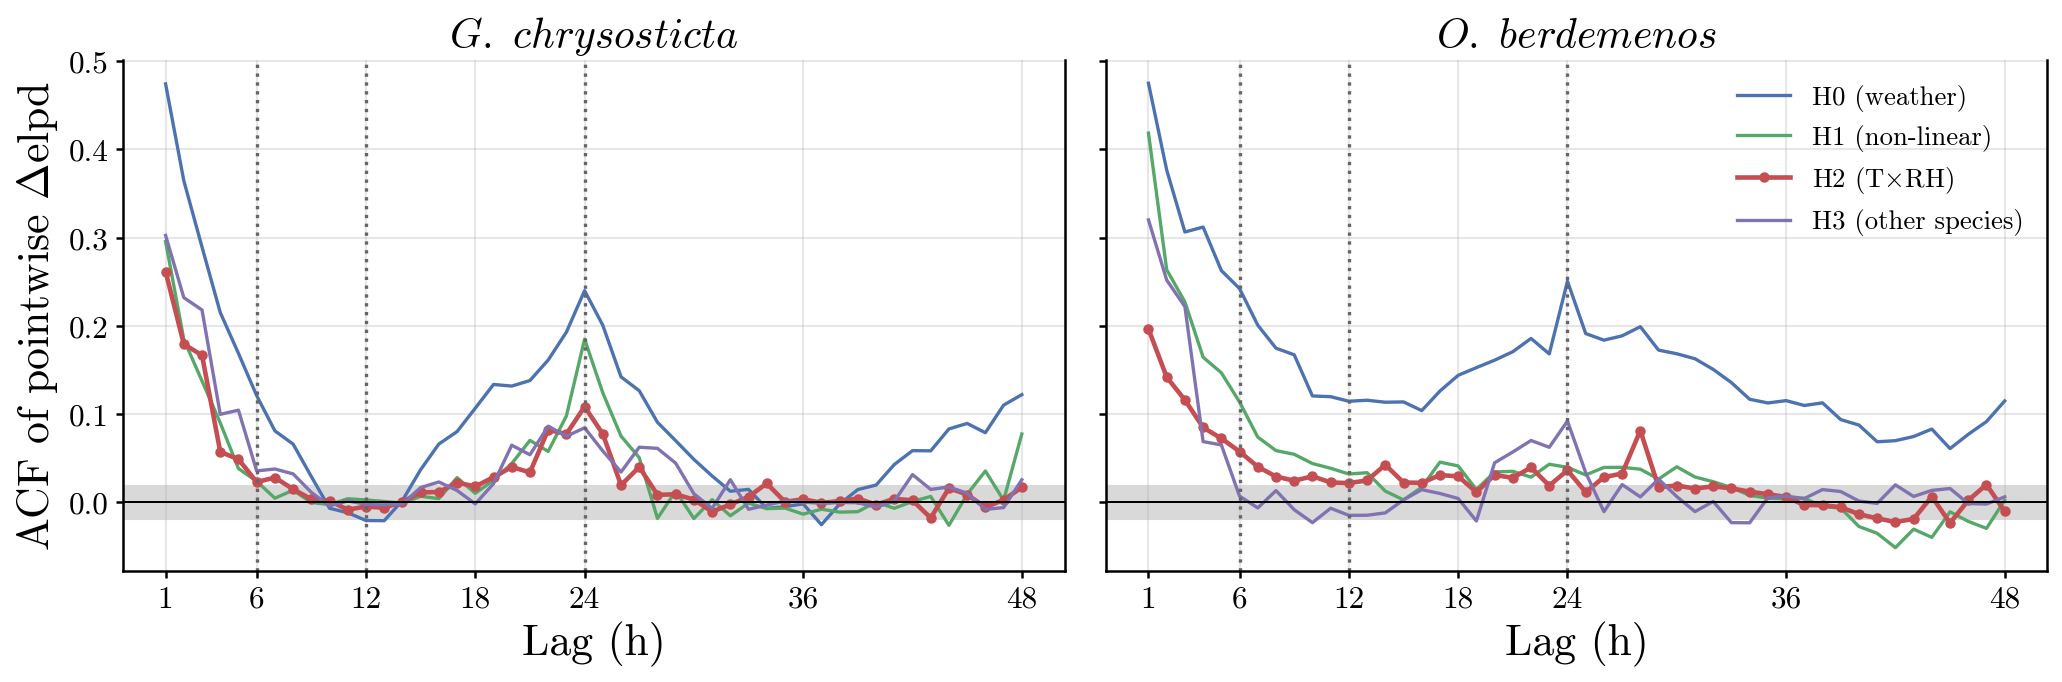

In [8]:
BL_K       = HS_K_REF          # block-length analysis at the main-analysis K
BL_HOURS   = [6, 12]           # hold-out block lengths (h)
ACF_MAXLAG = 48
ACF_THRESH = 0.05              # "negligible" autocorrelation, for the decorrelation lag


def gap_aware_acf(x: pd.Series, max_lag: int) -> np.ndarray:
    # ACF on the full hourly grid; pairs with a missing hour are dropped, not bridged.
    full = x.reindex(pd.date_range(x.index.min(), x.index.max(), freq="h"))
    v = full.values - np.nanmean(full.values)
    var = np.nanmean(v ** 2)
    return np.array([np.nanmean(v[:-L] * v[L:]) / var for L in range(1, max_lag + 1)])


acf_rows = []
for sp in SPECIES:
    idx = species_data[sp].index
    for hyp, adds, rich, simp in STEPS:
        d = pd.Series(psis_elpd_i[(sp, rich, BL_K)] - psis_elpd_i[(sp, simp, BL_K)], index=idx)
        for L, a in enumerate(gap_aware_acf(d, ACF_MAXLAG), start=1):
            acf_rows.append(dict(species=sp, species_short=SP_SHORT[sp], hypothesis=hyp, lag=L, acf=a))
acf_df = pd.DataFrame(acf_rows)
acf_df.to_csv(HS_TABLE_DIR / "block_length_delta_acf.csv", index=False)

ACF_BAND = 1.96 / np.sqrt(min(N_OBS.values()))


def decor_lag(a: pd.Series) -> int:
    # First lag from which the ACF stays below ACF_THRESH through lag 12.
    below = (a.values < ACF_THRESH)
    for i in range(len(below)):
        if below[i:12].all():
            return int(a.index[i])
    return np.nan


_t = (acf_df.pivot_table(index=["species_short", "hypothesis"], columns="lag", values="acf", sort=False))
acf_summary = pd.DataFrame({
    "lag 1": _t[1], "lag 3": _t[3], "lag 6": _t[6], "lag 12": _t[12], "lag 24": _t[24],
    "max |acf|, lags 13–48": _t.loc[:, 13:48].abs().max(axis=1),
    f"decorrelation lag (< {ACF_THRESH})": _t.apply(decor_lag, axis=1),
})
print(f"Gap-aware ACF of the pointwise Δelpd (hour PSIS-LOO, K = {BL_K}); "
      f"white-noise 95% band ±{ACF_BAND:.3f}")
display(acf_summary.round(3))

fig, axes = plt.subplots(1, len(SPECIES), figsize=(14, 4.8), sharey=True)
_hcol = dict(zip(HYPS, ["#4c72b0", "#55a868", "#c44e52", "#8172b2"]))
for ax, sp in zip(axes, SPECIES):
    for hyp in HYPS:
        a = acf_df.query("species == @sp and hypothesis == @hyp")
        ax.plot(a["lag"], a["acf"], color=_hcol[hyp], lw=LW_SECONDARY if hyp == "H2" else LW_AUX,
                marker="o" if hyp == "H2" else None, ms=4, label=f"{hyp} ({HYP_SHORT[hyp]})")
    ax.axhspan(-ACF_BAND, ACF_BAND, color="0.85", zorder=0)
    ax.axhline(0, color="k", lw=LW_AUX * 0.6)
    for L in BL_HOURS + [24]:
        ax.axvline(L, color="0.4", ls=":", lw=LW_AUX)
    ax.set_xticks([1, 6, 12, 18, 24, 36, 48])
    ax.set_xlabel("Lag (h)")
    ax.set_title(mathit(SP_SHORT[sp]))
axes[0].set_ylabel(r"ACF of pointwise $\Delta$elpd")
axes[-1].legend(frameon=False, fontsize=FS_LEGEND * 0.8)
fig.tight_layout()
savefig(fig, "delta_elpd_acf_block_length")
plt.show()

In [9]:
def block_labels(d: pd.DataFrame, hours: int, offset: int = 0) -> np.ndarray:
    # Blocks of `hours` consecutive hours, the first starting at `offset`:00.
    return (d.index - pd.Timedelta(hours=offset)).floor(f"{hours}h").values


def block_folds(blocks: np.ndarray) -> np.ndarray:
    rng = np.random.default_rng(CV_SEED)
    ub = np.unique(blocks)
    fd = dict(zip(rng.permutation(ub), np.arange(len(ub)) % CV_K))
    return np.array([fd[b] for b in blocks])


BL_SCHEMES = {f"block{h}h_kfold": (h, 0) for h in BL_HOURS}     # scheme → (hours, offset)
BL_SCHEMES["block12h_off6_kfold"] = (12, 6)                     # 06–18 h / 18–06 h: nights kept whole
for sp in SPECIES:
    for sc, (h, off) in BL_SCHEMES.items():
        FOLDS[sp][f"{sc}_cluster"] = block_labels(species_data[sp], h, off)
        FOLDS[sp][sc] = block_folds(FOLDS[sp][f"{sc}_cluster"])
    FOLDS[sp]["day_kfold_cluster"] = FOLDS[sp]["day"]

_todo = [(sp, m, sc) for sp in SPECIES for m in LADDER for sc in BL_SCHEMES
         if CV_REFIT or not cv_path(sp, m, BL_K, sc).exists()]
print(f"{len(SPECIES) * len(LADDER) * len(BL_SCHEMES) - len(_todo)} block-CV runs cached, "
      f"{len(_todo)} to compute ({len(_todo) * CV_K} ML refits)")
if _todo:
    _t0 = time.time()

    def _bjob(sp, m, sc):
        d = species_data[sp]
        X = dmatrix("0 + " + " + ".join(ladder_terms(m, BL_K)), d, return_type="dataframe")
        return cv_loglik(d["response_code"].values, X, FOLDS[sp][sc], CV_K)

    _out = Parallel(n_jobs=CV_N_JOBS, verbose=2)(delayed(_bjob)(*t) for t in _todo)
    for (sp, m, sc), (ll, n_bad) in zip(_todo, _out):
        np.savez_compressed(cv_path(sp, m, BL_K, sc), loglik_i=ll, n_nonconverged=n_bad)
    print(f"done in {(time.time() - _t0) / 60:.1f} min")

_conv = []
for sp in SPECIES:
    for m in LADDER:
        for sc in BL_SCHEMES:
            z = np.load(cv_path(sp, m, BL_K, sc))
            cv_loglik_i[(sp, m, BL_K, sc)] = z["loglik_i"]
            _conv.append(int(z["n_nonconverged"]))
for sp in SPECIES:
    for sc, (h, off) in BL_SCHEMES.items():
        nb_ = len(np.unique(FOLDS[sp][f"{sc}_cluster"]))
        print(f"  {SP_SHORT[sp]} {h:>2} h blocks from {off:02d}:00: {nb_} blocks, "
              f"{np.bincount(FOLDS[sp][sc]).min()}–{np.bincount(FOLDS[sp][sc]).max()} rows per fold")
print(f"✓ non-converged fold fits: {sum(_conv)} of {len(_conv) * CV_K}")

0 block-CV runs cached, 30 to compute (300 ML refits)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  3.6min finished


done in 3.6 min
  G. chrysosticta  6 h blocks from 00:00: 1884 blocks, 1127–1134 rows per fold
  G. chrysosticta 12 h blocks from 00:00: 942 blocks, 1126–1140 rows per fold
  G. chrysosticta 12 h blocks from 06:00: 943 blocks, 1121–1140 rows per fold
  O. berdemenos  6 h blocks from 00:00: 1884 blocks, 1127–1134 rows per fold
  O. berdemenos 12 h blocks from 00:00: 942 blocks, 1126–1140 rows per fold
  O. berdemenos 12 h blocks from 06:00: 943 blocks, 1121–1140 rows per fold
✓ non-converged fold fits: 0 of 300


✓ 1 h and 24 h rows reproduce §6


holdout                               1 h (PSIS-LOO)               6 h blocks    12 h blocks (00–12 h)    12 h blocks (06–18 h)        24 h (day) blocks
species_short   hypothesis                                                                                                                              
G. chrysosticta H0          +382.7 ± 25.0 (z=15.3) ✓  +379.6 ± 44.9 (z=8.5) ✓  +389.2 ± 47.9 (z=8.1) ✓  +380.5 ± 55.8 (z=6.8) ✓  +381.6 ± 57.2 (z=6.7) ✓
                H1           +105.1 ± 13.5 (z=7.8) ✓  +109.7 ± 21.4 (z=5.1) ✓  +109.3 ± 22.0 (z=5.0) ✓  +109.8 ± 24.4 (z=4.5) ✓  +109.6 ± 24.6 (z=4.5) ✓
                H2                +1.9 ± 4.1 (z=0.5)       +1.4 ± 3.7 (z=0.4)       +2.0 ± 3.8 (z=0.5)       +1.8 ± 4.2 (z=0.4)       +2.2 ± 4.2 (z=0.5)
                H3               -0.7 ± 0.8 (z=-1.0)      -0.5 ± 2.3 (z=-0.2)      -0.2 ± 2.3 (z=-0.1)      -3.7 ± 4.2 (z=-0.9)      -4.7 ± 3.6 (z=-1.3)
O. berdemenos   H0            +64.7 ± 10.3 (z=6.3) ✓   +48.4 ± 17.4 (z=2.8) ✓   +46.6 ± 19.5 (z=2.4) ✓     +42.9 ± 22.3 (z=1.9)     +43.1 ± 24.2 (z=1.8)
                H1             +11.8 ± 4.8 (z=2.5) ✓      +14.4 ± 8.6 (z=1.7)      +14.7 ± 9.3 (z=1.6)     +11.6 ± 10.9 (z=1.1)     +11.7 ± 10.6 (z=1.1)
                H2             +17.6 ± 6.1 (z=2.9) ✓      +16.8 ± 9.7 (z=1.7)     +17.7 ± 10.0 (z=1.8)      +8.9 ± 11.7 (z=0.8)     +11.6 ± 12.7 (z=0.9)
                H3                +0.9 ± 2.3 (z=0.4)      -3.3 ± 1.3 (z=-2.6)      -2.1 ± 1.0 (z=-2.2)      -4.1 ± 2.2 (z=-1.9)      -3.4 ± 1.8 (z=-1.9)

  saved figures/extra_blockcv_ladder_steps_block_length_K2.{pdf,png}


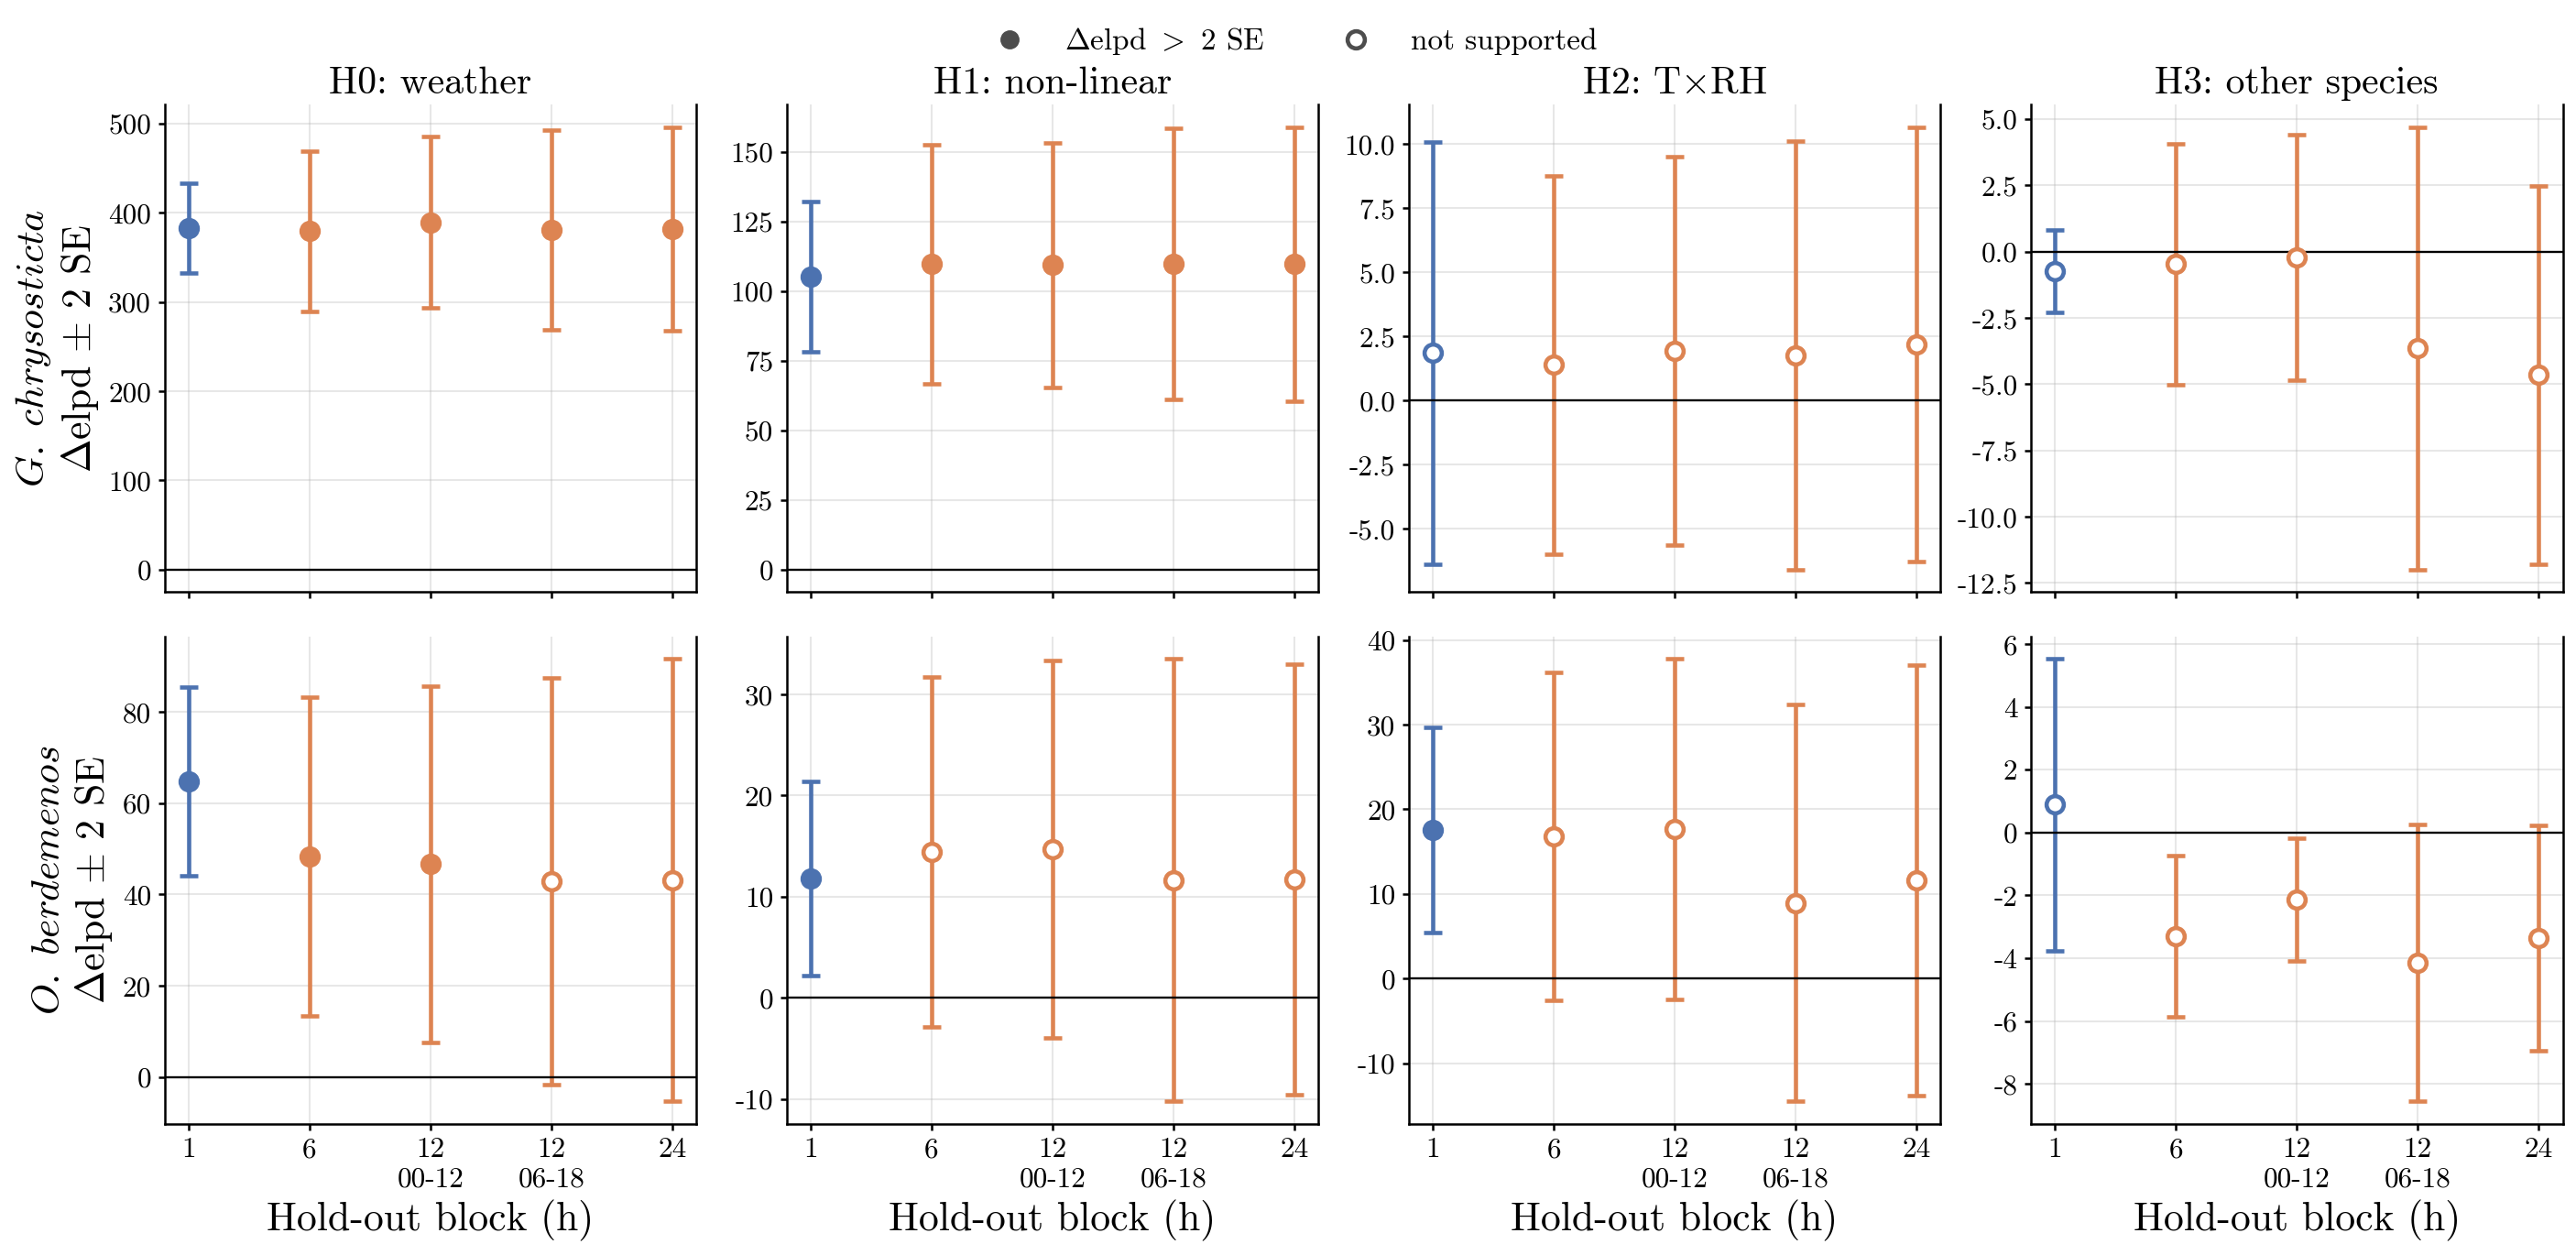

In [10]:
BL_ORDER = {"hour_psis":           ("1 h (PSIS-LOO)", "1"),
            "block6h_kfold":       ("6 h blocks", "6"),
            "block12h_kfold":      ("12 h blocks (00–12 h)", "12\n00-12"),
            "block12h_off6_kfold": ("12 h blocks (06–18 h)", "12\n06-18"),
            "day_kfold":           ("24 h (day) blocks", "24")}

_rows = []
for sp in SPECIES:
    for hyp, adds, rich, simp in STEPS:
        for sc, (lab, _) in BL_ORDER.items():
            cl = np.arange(N_OBS[sp]) if sc == "hour_psis" else FOLDS[sp][f"{sc}_cluster"]
            ed, se = contrast(pointwise(sp, rich, BL_K, sc) - pointwise(sp, simp, BL_K, sc), cl)
            _rows.append(dict(species=sp, species_short=SP_SHORT[sp], hypothesis=hyp, adds=adds,
                              richer=rich, simpler=simp, scheme=sc, holdout=lab,
                              n_clusters=len(np.unique(cl)), delta_elpd=ed, se=se, z=ed / se,
                              supported=ed > DECISIVE_SE * se))
blocklen = pd.DataFrame(_rows)
blocklen.to_csv(HS_TABLE_DIR / "block_length_steps_K2.csv", index=False)

# The 1 h and 24 h rows must be the §6 contrasts at K = BL_K.
_chk = blocklen.query("scheme in ['hour_psis', 'day_kfold']").merge(
    sweep.query("K == @BL_K"), on=["species", "hypothesis", "scheme"], suffixes=("", "_s6"))
assert np.allclose(_chk["delta_elpd"], _chk["delta_elpd_s6"]) and np.allclose(_chk["se"], _chk["se_s6"])
print("✓ 1 h and 24 h rows reproduce §6")

_tab = blocklen.assign(cell=lambda d: d.apply(
    lambda r: f"{r.delta_elpd:+.1f} ± {r.se:.1f} (z={r.z:.1f}){' ✓' if r.supported else ''}", axis=1))
display(_tab.pivot_table(index=["species_short", "hypothesis"], columns="holdout", values="cell",
                         aggfunc="first", sort=False)[[v[0] for v in BL_ORDER.values()]])

fig, axes = plt.subplots(len(SPECIES), len(HYPS), figsize=(19, 9), sharex=True)
_x = {sc: i for i, sc in enumerate(BL_ORDER)}
for i, sp in enumerate(SPECIES):
    for j, hyp in enumerate(HYPS):
        ax = axes[i, j]
        r = blocklen.query("species == @sp and hypothesis == @hyp").set_index("scheme")
        for sc in BL_ORDER:
            ok = r.loc[sc, "supported"]
            ax.errorbar(_x[sc], r.loc[sc, "delta_elpd"], yerr=DECISIVE_SE * r.loc[sc, "se"],
                        fmt="o", ms=9, capsize=CAPSIZE, lw=LW_SECONDARY,
                        color="#4c72b0" if sc == "hour_psis" else "#dd8452",
                        mfc=None if ok else "white", mew=LW_SECONDARY)
        ax.axhline(0, color="k", lw=LW_AUX * 0.7)
        ax.set_xticks(list(_x.values()), [str(v[1]) for v in BL_ORDER.values()])
        if i == 0:
            ax.set_title(f"{hyp}: {HYP_SHORT[hyp]}")
        if i == len(SPECIES) - 1:
            ax.set_xlabel("Hold-out block (h)")
        if j == 0:
            ax.set_ylabel(mathit(SP_SHORT[sp]) + "\n" + r"$\Delta$elpd $\pm$ 2 SE")
fig.legend(handles=[Line2D([], [], marker="o", ls="", ms=9, color="0.3", label=r"$\Delta$elpd $>$ 2 SE"),
                    Line2D([], [], marker="o", ls="", ms=9, color="0.3", mfc="white", mew=LW_SECONDARY,
                           label="not supported")],
           loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
savefig(fig, "ladder_steps_block_length_K2")
plt.show()

### Table S2 — ΔELPD (SE) by hold-out unit

1 h: PSIS-LOO (Bayesian fits); 6 h and 12 h: exact 10-fold CV with contiguous blocks starting at midnight
(and, for 12 h, a second scheme starting at 06:00); SE clustered by held-out block. The random-hour
10-fold control is listed alongside.

In [11]:
acf_summary.to_csv(HS_TABLE_DIR / "block_length_delta_acf_summary.csv")

TS2_SCHEMES = {"hour_psis": "1 h PSIS", "block6h_kfold": "6 h blocks", "block12h_kfold": "12 h blocks",
               "block12h_off6_kfold": "12 h blocks (06-18 h)", "hour_kfold": "random-hour 10-fold (control)"}
TS2_NAMES = {"H0": "Model 1 (weather)", "H1": "Model 2 (non-linear)", "H2": "Model 3 (T×RH)",
             "H3": "Model 4 (ordinal)"}
_ctrl = sweep.query("scheme == 'hour_kfold' and K == @BL_K")[["species", "hypothesis", "scheme", "delta_elpd", "se"]]
_t = pd.concat([blocklen[["species", "hypothesis", "scheme", "delta_elpd", "se"]], _ctrl], ignore_index=True)
_t = _t[_t["scheme"].isin(TS2_SCHEMES)]
_t["cell"] = _t.apply(lambda r: f"{r.delta_elpd:.1f} ({r.se:.1f})", axis=1)
tableS2 = (_t.pivot_table(index=["species", "hypothesis"], columns="scheme", values="cell",
                          aggfunc="first", sort=False)[list(TS2_SCHEMES)]
           .rename(columns=TS2_SCHEMES).reset_index())
tableS2["species"] = tableS2["species"].map(SP_SHORT)
tableS2.insert(2, "Model", tableS2["hypothesis"].map(TS2_NAMES))
tableS2 = tableS2.drop(columns="hypothesis").rename(columns={"species": "Species"})
tableS2.to_csv(fc.TABLE_DIR / "TableS2_blocked_cross_validation.csv", index=False)
tableS2

scheme,Species,Model,1 h PSIS,6 h blocks,12 h blocks,12 h blocks (06-18 h),random-hour 10-fold (control)
0,G. chrysosticta,Model 1 (weather),382.7 (25.0),379.6 (44.9),389.2 (47.9),380.5 (55.8),383.7 (26.6)
1,G. chrysosticta,Model 2 (non-linear),105.1 (13.5),109.7 (21.4),109.3 (22.0),109.8 (24.4),107.5 (14.5)
2,G. chrysosticta,Model 3 (T×RH),1.9 (4.1),1.4 (3.7),2.0 (3.8),1.8 (4.2),-0.8 (2.8)
3,G. chrysosticta,Model 4 (ordinal),-0.7 (0.8),-0.5 (2.3),-0.2 (2.3),-3.7 (4.2),0.0 (1.5)
4,O. berdemenos,Model 1 (weather),64.7 (10.3),48.4 (17.4),46.6 (19.5),42.9 (22.3),49.3 (10.0)
5,O. berdemenos,Model 2 (non-linear),11.8 (4.8),14.4 (8.6),14.7 (9.3),11.6 (10.9),13.9 (5.1)
6,O. berdemenos,Model 3 (T×RH),17.6 (6.1),16.8 (9.7),17.7 (10.0),8.9 (11.7),16.3 (7.8)
7,O. berdemenos,Model 4 (ordinal),0.9 (2.3),-3.3 (1.3),-2.1 (1.0),-4.1 (2.2),-0.3 (0.6)
